# Preços de combustíveis no Brasil (2013–2026): análise exploratória e estatística

**Autor:** Lucas Passos · **Fontes:** ANP (Levantamento de Preços de Combustíveis, média mensal por UF) e BCB (IPCA, série SGS 433)

## Perguntas

1. Quanto os combustíveis subiram **em termos reais**, descontada a inflação?
2. A política de preços da Petrobras mudou a **volatilidade** dos preços na bomba?
3. Existe **sazonalidade** no preço do etanol?
4. Em quais estados o etanol é **competitivo** com a gasolina, e com que frequência?
5. Os preços entre estados estão **convergindo** ou divergindo?
6. Qual foi a variação de preço associada ao **teto do ICMS** de julho de 2022?

Toda a lógica de dados está no pacote `src/combustiveis` (testado em `tests/`). O notebook só orquestra, visualiza e interpreta.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import logging
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

from combustiveis import config, metricas, pipeline, transformacao

logging.disable(logging.WARNING)
pd.options.display.float_format = "{:,.3f}".format

CORES = {"gasolina": "#d9480f", "etanol": "#2f9e44", "diesel": "#1c7ed6", "glp": "#7048e8"}
NOMES = {"gasolina": "Gasolina comum", "etanol": "Etanol hidratado", "diesel": "Diesel S10", "glp": "GLP (13 kg)"}
plt.rcParams.update({
    "figure.figsize": (11, 4.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "font.size": 10.5,
})
FIG = RAIZ / "docs" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

def salvar(fig, nome):
    fig.savefig(FIG / f"{nome}.png", bbox_inches="tight", dpi=140)

def ts(index):
    return index.to_timestamp()

## 1. Carga e validação dos dados

In [2]:
d = pipeline.carregar()
painel = d.painel
print(f"{len(painel):,} registros | {painel['uf'].nunique()} UFs | {painel['produto'].nunique()} produtos | "
      f"{painel['mes'].min()} a {painel['mes'].max()}")
print("Avisos de validação:", *d.relatorio.avisos, sep="\n  - ")
painel.head()

17,694 registros | 27 UFs | 4 produtos | 2013-01 a 2026-09
Avisos de validação:
  - diesel: sem dados em 2020-09
  - etanol: sem dados em 2020-09
  - gasolina: sem dados em 2020-09
  - glp: sem dados em 2020-09


,mes,produto,regiao,postos,preco,desvio,preco_min,preco_max,uf,preco_real
0,2013-01,diesel,Norte,3,2.630,0.081,2.590,2.750,AC,5.570
1,2013-02,diesel,Norte,13,2.697,0.092,2.670,3.020,AC,5.678
2,2013-03,diesel,Norte,26,2.766,0.119,2.670,3.020,AC,5.796
3,2013-04,diesel,Norte,41,2.813,0.114,2.739,3.100,AC,5.863
4,2013-05,diesel,Norte,57,2.807,0.080,2.730,3.100,AC,5.829


A validação (`combustiveis.validacao`) bloqueia o pipeline se houver UF não mapeada, chave `(mês, produto, UF)` duplicada, preço fora de faixa plausível ou média fora do intervalo [mínimo, máximo] informado pela ANP. O único aviso é **setembro de 2020**, mês em que a ANP suspendeu a pesquisa; ele fica como lacuna nas séries, sem interpolação.

In [3]:
painel.groupby("produto")[["preco", "postos"]].describe().T.round(2)

produto         diesel     etanol   gasolina       glp
preco  count 4,428.000  4,411.000  4,428.000 4,427.000
       mean      4.430      3.710      4.740    79.700
       std       1.570      1.030      1.320    27.450
       min       2.160      1.740      2.630    35.180
       25%       3.140      2.880      3.640    54.940
       50%       3.780      3.600      4.500    73.250
       75%       6.000      4.510      5.930   104.850
       max       8.420      6.980      8.120   142.810
postos count 4,428.000  4,411.000  4,428.000 4,427.000
       mean    570.490    782.960    875.750   728.130
       std     839.290  1,402.820  1,387.300 1,090.770
       min       1.000      1.000      2.000    11.000
       25%     153.000    157.000    214.000   172.000
       50%     270.000    283.000    417.500   370.000
       75%     699.250    792.500    940.000   803.500
       max   6,351.000 11,883.000 11,846.000 9,917.000

## 2. Preço nominal x preço real

Os preços foram deflacionados pelo IPCA e expressos em **reais de setembro de 2026**:
`preço_real(t) = preço(t) / I(t)`, onde `I` é o número-índice do IPCA com base 1 no último mês.

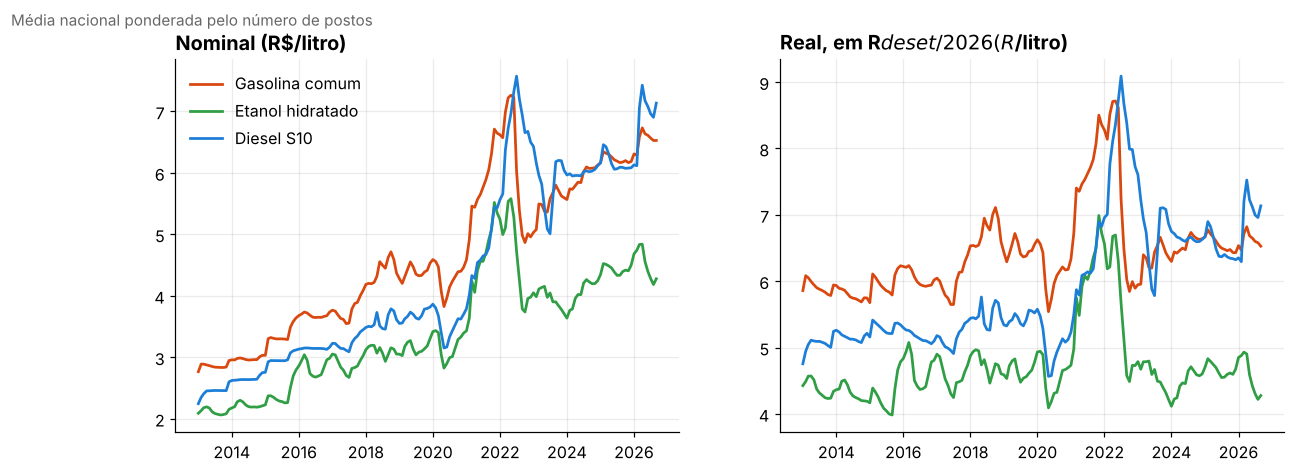

IPCA acumulado no período: 111.8%


,jan/2013 (nominal),set/2026 (nominal),variação nominal,variação real,pico real
produto,,,,,
Diesel S10,R$ 2.24,R$ 7.13,+218%,+50%,2022-07
Etanol hidratado,R$ 2.09,R$ 4.28,+105%,-3%,2021-11
Gasolina comum,R$ 2.77,R$ 6.53,+136%,+11%,2022-05
GLP (13 kg),R$ 40.69,R$ 115.48,+184%,+34%,2022-04


In [4]:
b, br = d.brasil, d.brasil_real
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=False)
for p in ["gasolina", "etanol", "diesel"]:
    axes[0].plot(ts(b.index), b[p], color=CORES[p], label=NOMES[p], lw=1.8)
    axes[1].plot(ts(br.index), br[p], color=CORES[p], label=NOMES[p], lw=1.8)
axes[0].set_title("Nominal (R$/litro)")
axes[1].set_title("Real, em R$ de set/2026 (R$/litro)")
axes[0].legend(frameon=False)
fig.suptitle("Média nacional ponderada pelo número de postos", x=0.01, ha="left", fontsize=10, color="0.4")
salvar(fig, "01_nominal_real"); plt.show()

ipca_acum = 1 / transformacao.indice_ipca(pipeline.ingestao.ler_ipca()).iloc[0] - 1
tabela = pd.DataFrame({
    "jan/2013 (nominal)": b.iloc[0], "set/2026 (nominal)": b.iloc[-1],
    "variação nominal": b.iloc[-1] / b.iloc[0] - 1, "variação real": br.iloc[-1] / br.iloc[0] - 1,
    "pico real": br.idxmax().astype(str),
}).rename(index=NOMES)
print(f"IPCA acumulado no período: {ipca_acum:.1%}")
tabela.style.format({"jan/2013 (nominal)": "R$ {:.2f}", "set/2026 (nominal)": "R$ {:.2f}",
                     "variação nominal": "{:+.0%}", "variação real": "{:+.0%}"})

**Leitura.** Com a inflação acumulada de cerca de 112%, quase toda a alta nominal da gasolina (+136%) é inflação: em termos reais ela subiu **11%**. O etanol está praticamente **no mesmo nível real de 2013** (−3%). Os itens que de fato encareceram foram o **diesel S10 (+50% real)** e o **gás de cozinha (+34% real)**, com efeito direto sobre frete e orçamento das famílias.

## 3. Volatilidade e política de preços da Petrobras

Volatilidade = desvio padrão dos retornos log mensais da média nacional, anualizado (× √12). Comparamos três regimes: preços administrados (até set/2016), **paridade de importação** (out/2016 a abr/2023) e a política comercial adotada em mai/2023.

,inicio,fim,gasolina,etanol,diesel
regime,,,,,
Preço administrado,2013-01,2016-09,6.3%,9.9%,5.2%
Paridade de importação (PPI),2016-10,2023-04,14.1%,15.9%,12.0%
Nova política comercial,2023-05,2026-09,5.2%,8.4%,13.1%


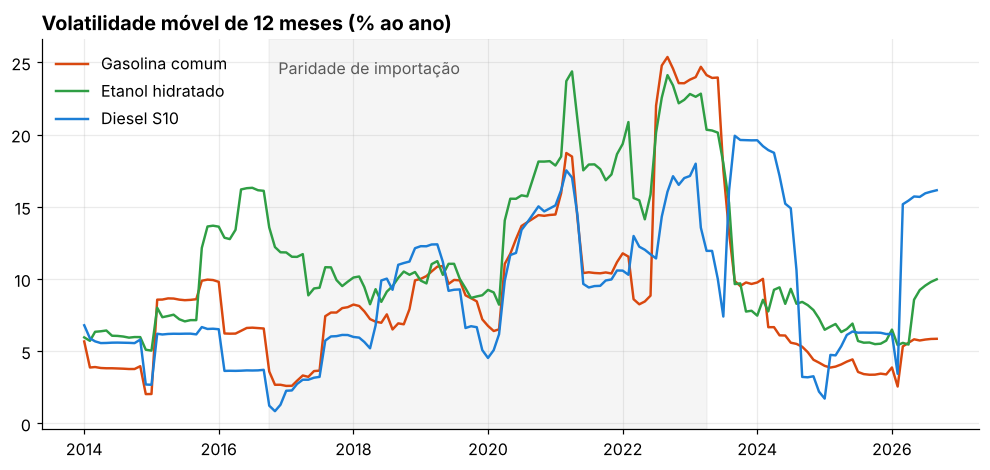

In [5]:
vol = metricas.volatilidade_por_regime(b[["gasolina", "etanol", "diesel"]])
display(vol.style.format({c: "{:.1%}" for c in ["gasolina", "etanol", "diesel"]}))

fig, ax = plt.subplots()
for p in ["gasolina", "etanol", "diesel"]:
    v = metricas.volatilidade_movel(b[p])
    ax.plot(ts(v.index), v * 100, color=CORES[p], label=NOMES[p], lw=1.6)
ini, fim = pd.Period("2016-10", "M").to_timestamp(), pd.Period("2023-04", "M").to_timestamp()
ax.axvspan(ini, fim, color="0.5", alpha=0.08)
ax.text(ini, ax.get_ylim()[1] * 0.95, "  Paridade de importação", color="0.35", va="top")
ax.set_title("Volatilidade móvel de 12 meses (% ao ano)")
ax.legend(frameon=False, loc="upper left")
salvar(fig, "02_volatilidade"); plt.show()

**Leitura.** No período de paridade de importação a volatilidade da gasolina foi **2,2 vezes** a do período anterior (14,1% contra 6,3% ao ano), porque o preço passou a acompanhar petróleo e câmbio. Depois de mai/2023 a gasolina voltou ao patamar pré-2016 (5,2%), mas o **diesel continuou volátil** (13,1%), o que sugere repasse mais frequente das variações internacionais nesse produto.

*Ressalva:* a comparação é descritiva. Os regimes coincidem com choques externos (pandemia, guerra), então não isolam o efeito da política.

## 4. Sazonalidade do etanol

Para separar sazonalidade de tendência, calculamos o desvio do log do preço em relação a uma média móvel centrada 2×12 e tiramos a média por mês do calendário.

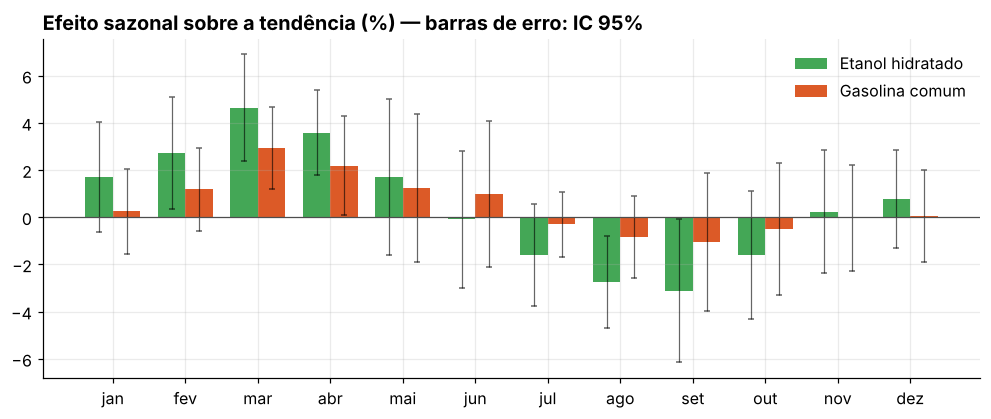

mes,1,2,3,4,5,6,7,8,9,10,11,12
efeito_pct,1.720,2.720,4.640,3.580,1.700,-0.090,-1.610,-2.750,-3.110,-1.610,0.240,0.770
erro_padrao,1.190,1.220,1.150,0.920,1.680,1.480,1.100,1.000,1.560,1.390,1.340,1.070
n,13.000,13.000,13.000,13.000,12.000,12.000,12.000,13.000,12.000,13.000,13.000,13.000


In [6]:
saz = {p: metricas.sazonalidade(b[p]) for p in ["etanol", "gasolina"]}
meses_pt = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(12)
for i, p in enumerate(["etanol", "gasolina"]):
    s = saz[p]
    ax.bar(x + (i - 0.5) * 0.38, s["efeito_pct"], 0.38, yerr=1.96 * s["erro_padrao"], capsize=2,
           color=CORES[p], alpha=0.9, label=NOMES[p], error_kw={"lw": 0.8, "alpha": 0.6})
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xticks(x, meses_pt)
ax.set_title("Efeito sazonal sobre a tendência (%) — barras de erro: IC 95%")
ax.legend(frameon=False)
salvar(fig, "03_sazonalidade"); plt.show()
saz["etanol"].round(2).T

**Leitura.** O etanol tem um ciclo claro: fica **4,6% acima da tendência em março** e **3,1% abaixo em setembro**, uma amplitude de quase 8 pontos. O padrão coincide com o calendário da cana no Centro-Sul: a entressafra (dez–mar) reduz a oferta e a safra (abr–nov) a amplia. A gasolina, cujo preço segue petróleo e política de preços, não mostra padrão relevante. **Implicação prática:** a vantagem do etanol tende a ser maior no segundo semestre.

## 5. Competitividade do etanol por estado

Pela regra de paridade energética, o etanol compensa quando custa até **70%** da gasolina.

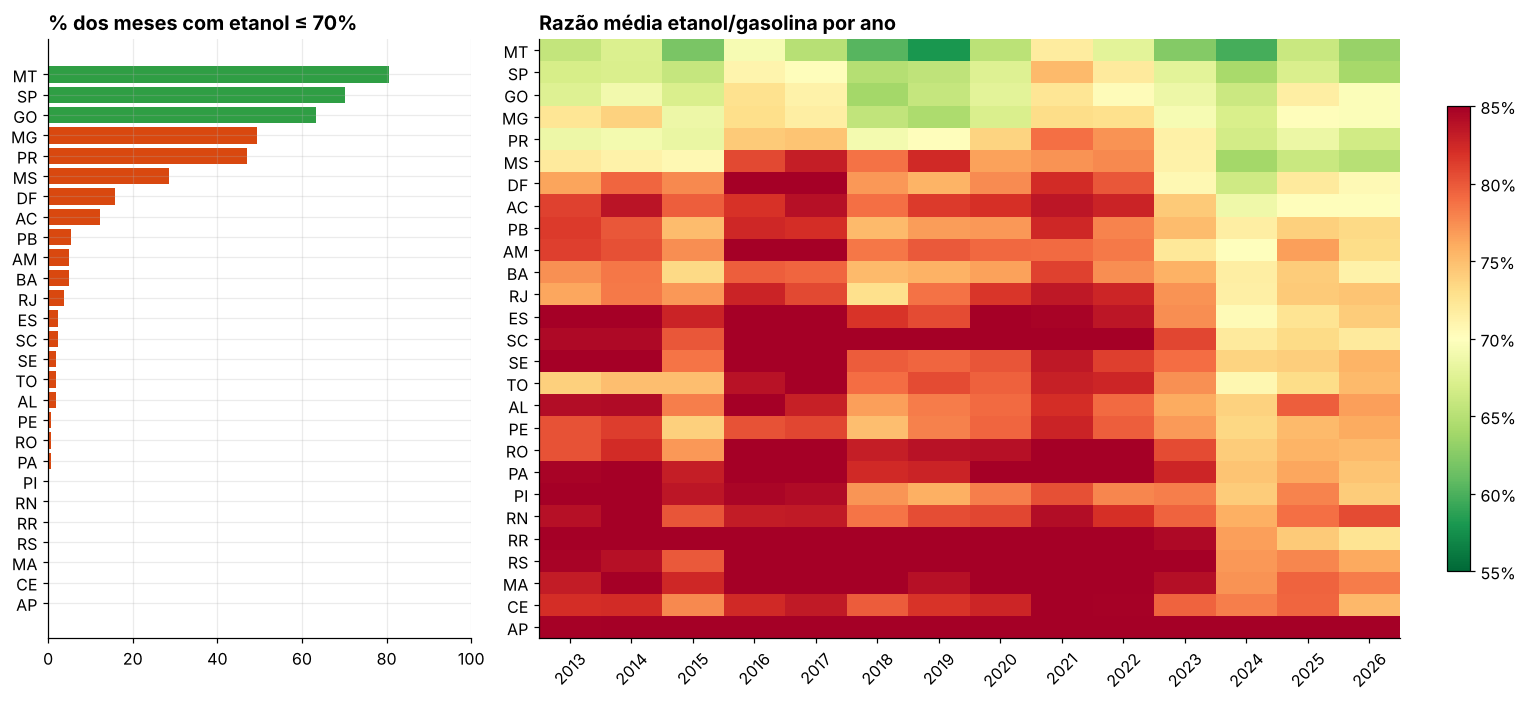

Estados onde o etanol compensa em 2026-09 -> SP, MT, MS, PR, GO, DF, AC, MG, BA, SC, PA, RO


In [7]:
razao = transformacao.razao_etanol_gasolina(painel)
share = metricas.participacao_paridade(razao)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 2.2]})
cores = [CORES["etanol"] if v >= 0.5 else CORES["gasolina"] for v in share.values]
axes[0].barh(share.index[::-1], share.values[::-1] * 100, color=cores[::-1])
axes[0].set_title("% dos meses com etanol ≤ 70%")
axes[0].set_xlim(0, 100)

anual = razao.groupby(razao.index.year).mean().T.loc[share.index]
im = axes[1].imshow(anual.values, aspect="auto", cmap="RdYlGn_r", vmin=0.55, vmax=0.85)
axes[1].set_yticks(range(len(anual)), anual.index)
axes[1].set_xticks(range(len(anual.columns)), anual.columns, rotation=45)
axes[1].set_title("Razão média etanol/gasolina por ano")
axes[1].grid(False)
fig.colorbar(im, ax=axes[1], fraction=0.025, format=lambda v, _: f"{v:.0%}")
fig.tight_layout()
salvar(fig, "04_paridade_etanol"); plt.show()

ultimo = razao.iloc[-1].sort_values()
print("Estados onde o etanol compensa em", razao.index[-1], "->", ", ".join(ultimo[ultimo <= 0.7].index))

**Leitura.** A competitividade do etanol é **estrutural e geográfica**: Mato Grosso (80% dos meses), São Paulo (70%) e Goiás (63%), estados produtores ou vizinhos às usinas, concentram os casos favoráveis. Em **sete estados o etanol não compensou em nenhum mês** desde 2013: Amapá, Ceará, Maranhão, Piauí, Rio Grande do Norte, Roraima e, apesar de ser um grande mercado, Rio Grande do Sul. O mapa de calor mostra que 2021–2022 foi o período menos favorável em quase todo o país, e que o etanol voltou a ganhar espaço depois.

## 6. Dispersão de preços entre estados

Coeficiente de variação (CV) da gasolina entre as 27 UFs em cada mês, com tendência linear.

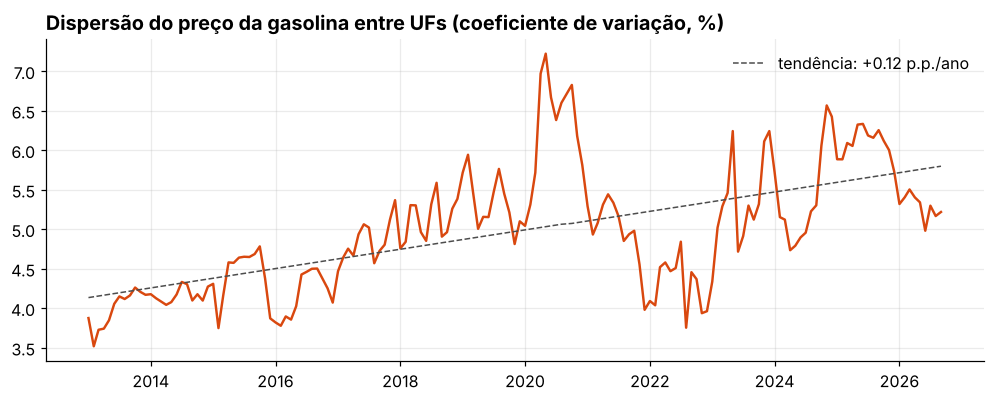

CV médio 2013: 4.0% | CV médio últimos 12 meses: 5.5%


In [8]:
gas = transformacao.tabela_larga(painel, "gasolina")
cv = metricas.dispersao_regional(gas).dropna()
t = np.arange(len(cv))
coef = np.polyfit(t, cv.values * 100, 1)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(ts(cv.index), cv * 100, color=CORES["gasolina"], lw=1.6)
ax.plot(ts(cv.index), np.polyval(coef, t), color="0.3", ls="--", lw=1, label=f"tendência: {coef[0] * 12:+.2f} p.p./ano")
ax.set_title("Dispersão do preço da gasolina entre UFs (coeficiente de variação, %)")
ax.legend(frameon=False)
salvar(fig, "05_dispersao"); plt.show()
print(f"CV médio 2013: {cv.loc['2013'].mean():.1%} | CV médio últimos 12 meses: {cv.iloc[-12:].mean():.1%}")

**Leitura.** Os preços entre estados estão **divergindo**: o CV subiu de 4,0% em 2013 para 5,5% nos últimos 12 meses (tendência de +0,12 p.p. por ano). A exceção é o período entre **nov/2021 e dez/2022**, quando a dispersão ficou em torno de 4%: é justamente quando o ICMS dos combustíveis foi congelado pelos estados (nov/2021) e depois limitado pela LC 194 (jul/2022). Com a mudança de regras em 2023, ela voltou a subir, o que indica que o imposto estadual é um dos principais motores das diferenças entre estados. Hoje a diferença entre o estado mais caro (RR) e o mais barato (RS) é de **R$ 1,34 por litro**, puxada principalmente pelo custo logístico do Norte.

## 7. Teto do ICMS (LC 194/2022): regressão de série interrompida

Modelo em log do preço real nacional, com janela de 12 meses antes e depois de jul/2022:

$$\log p_t = \beta_0 + \beta_1 t + \beta_2 D_t + \beta_3 (t - t_0) D_t + \varepsilon_t$$

$D_t = 1$ a partir da intervenção; $\beta_2$ é a mudança imediata de nível. Erros padrão **HAC (Newey-West, 3 defasagens)** por causa da autocorrelação dos resíduos.

,mudança de nível,IC 95% inf,IC 95% sup,p-valor,n
Gasolina comum,-28.5%,-35.0%,-21.4%,3.9e-12,24
Etanol hidratado,-23.8%,-30.7%,-16.2%,2.2e-08,24
Diesel S10,+3.7%,-1.0%,+8.6%,0.13,24


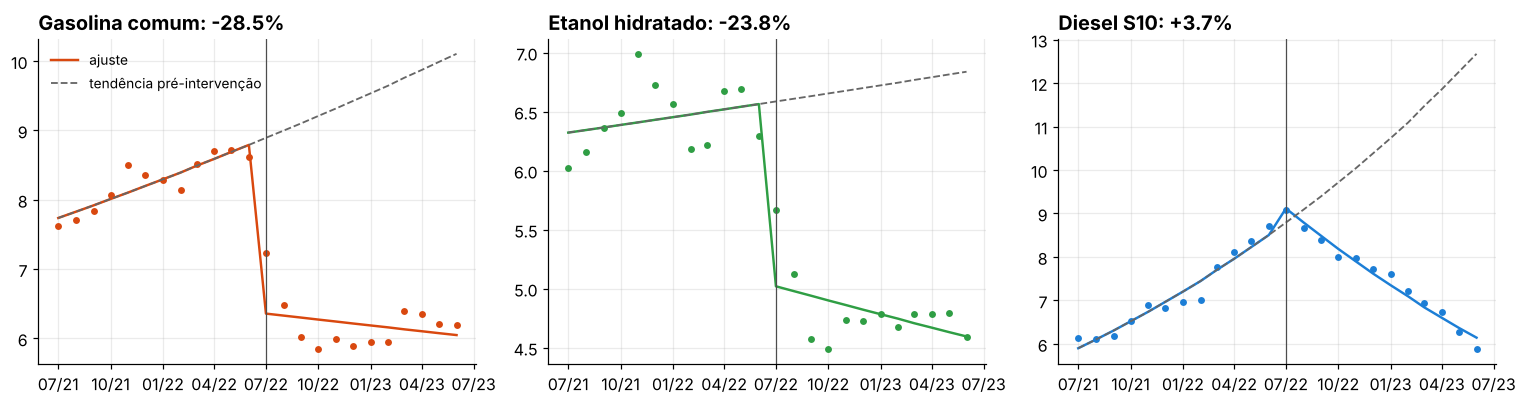

In [9]:
res = {p: metricas.serie_interrompida(br[p]) for p in ["gasolina", "etanol", "diesel"]}
tab = pd.DataFrame({NOMES[p]: {"mudança de nível": r.mudanca_nivel / 100, "IC 95% inf": r.ic95[0] / 100,
                               "IC 95% sup": r.ic95[1] / 100, "p-valor": r.p_valor, "n": r.n}
                    for p, r in res.items()}).T
display(tab.style.format({"mudança de nível": "{:+.1%}", "IC 95% inf": "{:+.1%}", "IC 95% sup": "{:+.1%}",
                          "p-valor": "{:.2g}", "n": "{:.0f}"}))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=False)
t0 = pd.Period(config.MES_INTERVENCAO_ICMS, "M")
for ax, (p, r) in zip(axes, res.items()):
    s = br[p].dropna().loc[t0 - 12: t0 + 11]
    m = r.modelo
    X = m.model.exog.copy()
    contrafactual = np.exp(X[:, 0] * m.params[0] + X[:, 1] * m.params[1])
    ax.plot(ts(s.index), s.values, "o", ms=3.5, color=CORES[p])
    ax.plot(ts(s.index), np.exp(m.fittedvalues), color=CORES[p], lw=1.6, label="ajuste")
    ax.plot(ts(s.index), contrafactual, color="0.4", ls="--", lw=1.2, label="tendência pré-intervenção")
    ax.axvline(t0.to_timestamp(), color="0.3", lw=0.8)
    ax.set_title(f"{NOMES[p]}: {r.mudanca_nivel:+.1f}%")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()
salvar(fig, "06_icms_its"); plt.show()

In [10]:
robustez = pd.DataFrame({NOMES[p]: metricas.robustez_its(br[p])["mudanca_nivel_pct"] for p in ["gasolina", "etanol", "diesel"]})
robustez.index.name = "janela (meses)"
robustez.style.format("{:+.1f}%")

,Gasolina comum,Etanol hidratado,Diesel S10
janela (meses),,,
6,-22.9%,-18.6%,-2.8%
9,-25.6%,-19.9%,+0.6%
12,-28.5%,-23.8%,+3.7%
18,-32.0%,-28.2%,-1.4%
24,-33.4%,-32.0%,-4.3%


**Leitura.** Há uma quebra de nível estatisticamente significativa de **−28,5% na gasolina** (IC 95%: −35% a −21%) e **−24% no etanol**, enquanto o **diesel não mostra quebra** (IC inclui zero). O resultado é robusto ao tamanho da janela: entre 6 e 24 meses, a queda da gasolina fica entre −23% e −33%.

O contraste com o diesel é coerente com o mecanismo: a alíquota de ICMS da gasolina era bem maior (em vários estados acima de 25%) do que a do diesel, então o teto teve muito mais efeito sobre ela.

**Limitação importante:** no mesmo período a Petrobras reduziu o preço da gasolina nas refinarias e as cotações do petróleo recuaram. O desenho não separa esses fatores, então o número deve ser lido como a **variação total associada ao período da intervenção**, não como o efeito isolado do imposto. Um desenho causal mais forte usaria dados de alíquota por estado (diferenças em diferenças com intensidade de tratamento).

## 8. Conclusões

| Pergunta | Resposta |
|---|---|
| Alta real desde 2013 | Gasolina +11%, etanol −3%, diesel S10 +50%, GLP +34% (IPCA acumulado: 112%) |
| Volatilidade | 2,2× maior na paridade de importação; gasolina voltou ao patamar anterior após 2023, diesel não |
| Sazonalidade | Etanol +4,6% em março e −3,1% em setembro, em linha com a safra de cana |
| Etanol competitivo | Estrutural no Centro-Oeste e em SP; nunca competitivo em AP, CE, MA, PI, RN, RR e RS |
| Dispersão entre UFs | Em alta: CV de 4,0% (2013) para 5,5% (últimos 12 meses); comprimida entre nov/2021 e dez/2022, durante o congelamento e o teto do ICMS |
| Teto do ICMS | Quebra de −28,5% na gasolina e −24% no etanol; sem efeito no diesel |

### Limitações
- Médias mensais estaduais escondem a variação entre municípios e postos.
- A amostra da ANP mudou ao longo do tempo (ex.: redução de municípios em 2017; pesquisa suspensa em set/2020).
- As análises de volatilidade e ICMS são associações temporais, sem identificação causal completa.

### Próximos passos
- Incluir Brent e câmbio para medir a velocidade de repasse (pass-through) em cada regime.
- Usar alíquotas de ICMS por UF para estimar o efeito do teto com diferenças em diferenças.
- Descer ao nível de município com os microdados semestrais da ANP.